# Anvendt KI og ML: Innsendingsoppgave – Salgsprediksjoner
Velkommen til denne Jupyter notebooken, som du skal bruke til den første obligatoriske innsendingsoppgaven i Høyskolen Kristianias emne «Anvendt kunstig intelligens og maskinlæring».

## Hvordan du bruker denne notebooken 
Du skal gå gjennom denne notebooken for å løse innsendingsoppgaven. Underveis skal du skrive kode som løser hver av de 7 kodeoppgavene skrevet _i kursiv_. Skriv kode inn i kodecellen rett under oppgaven, og legg gjerne til flere kodeceller. Du kan finne og gjenbruke relevant kode i notebooks i emnets modul 1, 2 og 3, og her i oppgaveteksten. Du kan eventuelt bruke andre programmeringsspråk etter avtale med veilederen din, men alle kodehint er gitt for Python.

Underveis vil du også finne 13 fritekstoppgaver du må besvare tekstlig. Også disse er skrevet _i kursiv_. De skal besvares i markdowncellene rett under oppgavene. Referer til egen kode der det er relevant.

Hvis du står fast, kontakt veilederen din for å få hjelp til å komme videre (via «Innboks» i hovedmenyen i Canvas, _ikke_ klikk «Lever oppgave»).

Etter at du har lagt inn egen tekst og kode for hver oppgave, skal du levere inn en PDF-versjon av denne notebooken. PDF-en skal vise både den skriftlige besvarelsen din og output fra alle kodecellene. Du eksporterer notebooken fra JupyterLab via File-menyen -> Print... I utskriftvinduet velger du «Lagre som PDF» i feltet Destinasjon.

## Problemstilling: Predikere salg av matprodukter (fiktivt eksempel)
Du har fått i oppgave fra Indiske Matgrossisters Forening å utvikle en modell som skal predikere salg av produkter i forskjellige typer matbutikker. De ønsker en modell der de kan oppgi noen karakteristika for produktet og butikken, og så få et estimat for salget. Kunden, det vil si Indiske Matgrossisters Forening, har testdataene. Du får kun utlevert dataene som brukes til trening og validering.

_**Fritekstoppgave**:_

1. _Hva er en god baselinemodell for dette problemet?_

**Svar**:

En baseline modell skal gi oss et utgangspunkt eller Status Quo som skal forbedres mgjennom bruk av en prediksjonsalgoritme.
En enkel baseline modell for denne casen kan være en modell som predikerer gjennomsnitts-salgstall av produktene i sine respektive matbutikkene.  

Hvis vi har tilgang til mer data, kan vi også komme til en bedre baseline modell:
Har vi informasjon om produktene, sine karakteristika og salgstall fra de froskjellige type matbutikker fra 4-5 år tilbake, kan vi trene en bedre baseline modell. Vi må da f.eks ha og bruke data fra fjoråret som testdata. Data fra 2 år tilbake som valideringsdata og data fra 3-5 år tilbake som treningsdata. Årene blir i så fall også en karateristikk som må tas hensyn til. 

## Pakker og nyttige funksjoner

In [1]:
# Du må først kjøre denne cellen for å importere relevante biblioteker
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Vi velger å ignorere advarsler
import warnings
warnings.filterwarnings('ignore',category = FutureWarning)

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
import seaborn as sns
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.metrics import mean_squared_error,r2_score
import xgboost as xgb

In [2]:
# Her er hjelpefunksjonene fra modul 1. Du må kjøre denne cellen for å bruke funksjonene.

def make_scatter_plot(data, para1, para2, logx=False, logy=False):
    plt.plot(data[para1], data[para2], '*', alpha=0.1)
    if logx:
        plt.xscale("log")
    if logy:
        plt.yscale('log')
    plt.xlabel(para1)
    plt.ylabel(para2)

def corr_heatmap(df, figsize=(10, 10)):
    _, axs = plt.subplots(figsize=figsize)
    ax = sns.heatmap(
        df, vmin=-1, vmax=1, cmap="BrBG", linewidths=0.5, annot=True, ax=axs)
    ax.set_title('Correlation matrix')
    return ax

def make_histogram(data, variable, binwidth, lower_lim=None, upper_lim=None):
    if upper_lim == None:
        upper_lim = data[variable].max()
    if lower_lim == None:
        lower_lim = data[variable].min()
    bins=np.arange(lower_lim, upper_lim + binwidth, binwidth)
    plt.hist(data[variable],bins=bins,edgecolor = 'black',alpha=0.75,range = [data[variable].min(),upper_lim])
    plt.ylabel("antall")
    plt.xlabel(variable)

## Dataene
Dataene er hentet fra flere ulike matbutikker i India. Vi har disse variablene:
- **ProductID**: En ID som unikt identifiserer produktet. 
- **FatContent**: Om produktet har lavt fettinnhold eller ikke.
- **Visibility**: Hvor synlig produktet er i butikken. Er skalert til å være et tall mellom 0 og 1. 
- **StoreType**: Hva slags type butikk det er. I Norge ville dette ha tilsvart ulike kjeder.
- **Size Store**: Butikkens størrelse gitt som kategori.
- **MRP**: Maximum retail price (https://en.wikipedia.org/wiki/Maximum_retail_price). Merk at MRP kan være forskjellig for samme produkt, avhengig av hvor butikken ligger. 
- **Sales**: Totalt salg av gitt produkt i butikken. Valuta er rupi.

Hver kolonne i datasettet representerer det totale salget av et gitt produkt i en bestemt butikk i 2018.

In [3]:
# Vi laster dataene inn i en pandas dataframe. Deretter kan vi begynne å jobbe med dataene.

frame=pd.read_csv("data/sales_data.csv")

### Få oversikt over dataene
_**Kodeoppgave 1**:_
- _Få en rask oversikt over dataene._

> **Hint:** Her kan du gjerne bruke pandas' `describe`-funksjon, og du kan bruke `isna`-funksjonen for å finne `NaN`-verdier (dvs. verdier som er «Not a Number»). Koden kan f.eks. se slik ut:
>```
># For numeriske verdier (default setting er å ekskludere kategoriske variabler):
>frame.describe()
>
># For kategoriske verdier:
>frame.describe(exclude=[np.number])
>
># Finn NaN-verdier
>frame.isna().sum()
```

In [4]:
# Studentkode

frame.describe()

,Visibility,MRP,Sales
count,5000.000000,5000.000000,5000.000000
mean,-5.973329,141.344520,2188.381667
std,23.712860,62.401514,1703.131187
min,-99.000000,31.290000,33.290000
25%,0.026839,94.119250,846.231800
50%,0.054251,143.315400,1808.312800
75%,0.093850,186.472700,3091.975200
max,0.328391,266.888400,11445.102000


In [5]:
frame.describe(exclude=[np.number])

,ProductID,FatContent,StoreType,SizeStore
count,5000,5000,5000,3561
unique,1538,5,4,3
top,DRE49,Low Fat,Supermarket Type1,Medium
freq,8,3008,3328,1605


In [6]:
# Studentkode: Øsnker å ta en titt på data head for å skaffe meg oversikt med de første linjenene av tabellen sammen. 
#Koden er tatt fra notebook til modul1

frame.head()

,ProductID,FatContent,Visibility,StoreType,SizeStore,MRP,Sales
0,FDA15,Low Fat,0.016047,Supermarket Type1,Medium,249.8092,3735.1380
1,DRC01,Regular,0.019278,Supermarket Type2,Medium,48.2692,443.4228
2,FDN15,Low Fat,0.016760,Supermarket Type1,Medium,141.6180,2097.2700
3,FDX07,Regular,-99.000000,Grocery Store,NaN,182.0950,732.3800
4,NCD19,Low Fat,-99.000000,Supermarket Type1,High,53.8614,994.7052


In [7]:
#Studentkode: Skal se nøyere på NaN verdiene
frame.isna().sum()

ProductID        0
FatContent       0
Visibility       0
StoreType        0
SizeStore     1439
MRP              0
Sales            0
dtype: int64

&nbsp;<br>
_**Fritekstoppgaver**:_

2. _Hvor mange datapunkter har vi?_
3. _Hva er gjennomsnittlig salgspris?_
4. _Hvor mange forskjellige ProductID har vi?_

**Svar**:
Fra Oversiktstabellen:
Vi har 5000 datapunkter
Gjennomsnittlig salgspris er 2188.38166 rupi.
Vi har 1538 forskjellige Product IDs

### Utforsk variablene hver for seg
_**Kodeoppgave 2**:_
- _Utforsk alle variablene hver for seg._

>**Hint:**
>Du kan bruke funksjonen `frame.hist()`
>for å raskt lage histogrammer for de numeriske variablene, men bruk gjerne hjelpefunksjonene (som er lagt til toppen av notebooken) for å studere histogrammene i detalj.
>For de kategoriske variablene, er det lurt å bruke `value_counts(dropna=False)` istedenfor vanlig value counts, slik at du også får med verdier som er NaN.

array([[<Axes: title={'center': 'Visibility'}>,
        <Axes: title={'center': 'MRP'}>],
       [<Axes: title={'center': 'Sales'}>, <Axes: >]], dtype=object)

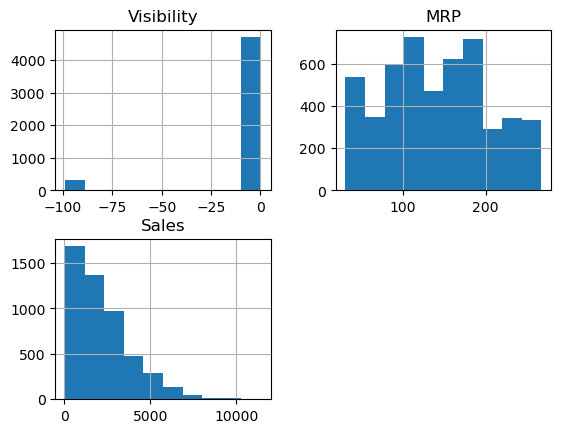

In [8]:
# Studentkode: Utforsker numeriske verdier

frame.hist()

In [9]:
#Studentkode: Utforsker kategoriske verdier:
frame["FatContent"].value_counts()

FatContent
Low Fat    3008
Regular    1679
LF          183
reg          68
low fat      62
Name: count, dtype: int64

In [10]:
#Studentkode: Utforsker kategoriske verdier:
frame["StoreType"].value_counts()

StoreType
Supermarket Type1    3328
Grocery Store         608
Supermarket Type3     538
Supermarket Type2     526
Name: count, dtype: int64

In [11]:
#Studentkode: Utforsker kategoriske verdier:
frame["SizeStore"].value_counts(dropna=False)

SizeStore
Medium    1605
NaN       1439
Small     1398
High       558
Name: count, dtype: int64

In [12]:
#Studentkode: Ønsker også en nærmere titt på -99 veridene i Visibility
frame["Visibility"].value_counts()

Visibility
-99.000000    305
 0.058121       2
 0.080640       2
 0.052150       2
 0.107274       2
             ... 
 0.012002       1
 0.136697       1
 0.028653       1
 0.046609       1
 0.027455       1
Name: count, Length: 4654, dtype: int64

In [13]:
#Studentcode: Prøver med en correlation Heat map også (kode tatt fra Modul 3 notebooken):
def corr_heatmap(df, figsize=(10, 10)):
    _, axs = plt.subplots(figsize=figsize)
    ax = sns.heatmap(
        df, vmin=-1, vmax=1, cmap="BrBG", linewidths=0.5, annot=True, ax=axs)
    ax.set_title('Correlation matrix')
    return ax

In [14]:
#Studentkode: begrenser til de 2 relevante kolonnene 
#(kodetilpasning funnet med hjelp av Anaconda Assistent som jeg sporte etter en begrensning av correlation matrix til utvalgte colonner i pandas):
selected_columns = ["MRP", "Sales" , "Visibility"]

In [15]:
#Studentkode 
correlation = frame[selected_columns].corr()

<Axes: title={'center': 'Correlation matrix'}>

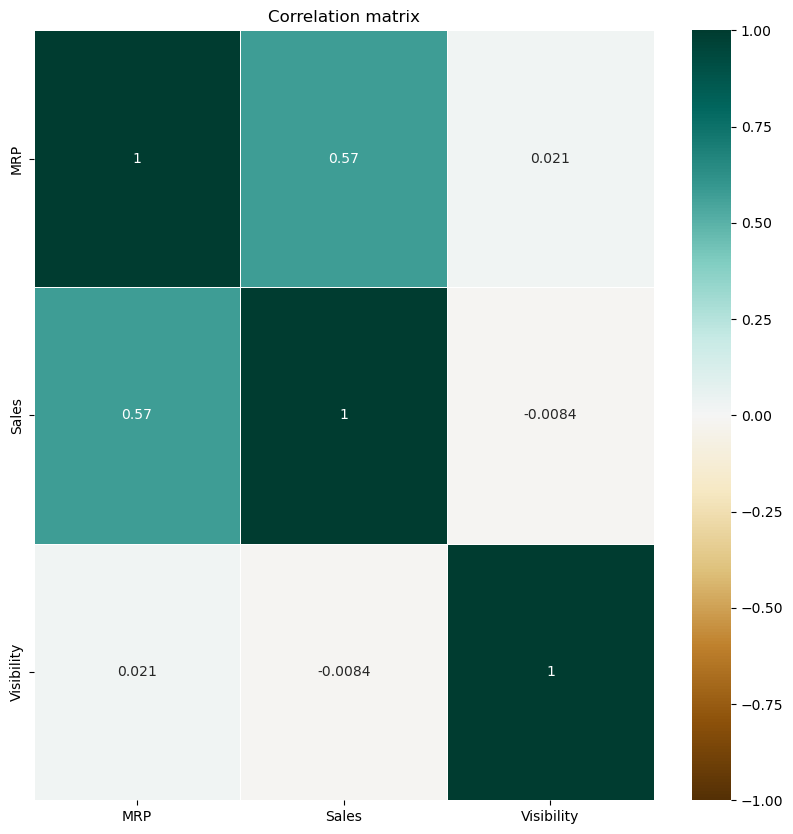

In [16]:
#Studentkode 
corr_heatmap(correlation)

_**Fritekstoppgaver**:_

5. _Du bør nå ha funnet minst to (vi vet om tre) datakvalitetsproblemer. Beskriv dem._
6. _Du kan komme deg rundt et av datakvalitetsproblemene ved å rette opp det som er feil, hvis du har gode grunner til å anta hva det skal rettes til. Hvis du ikke kan gjøre noen slike antagelser, kan du fylle inn gjennomsnittet eller den mest vanlige verdien. Du kan også velge å fjerne alle rader med et gitt datakvalitetproblem. For hver av datakvalitetsproblemene, velg en strategi og begrunn hvorfor._
7. _Du skal ta vekk kolonnen for ProductID. Kan du forklare hvorfor?_

>**Hint 1**: To av problemene har med manglende verdier å gjøre, og ett har med skrivemåter å gjøre.
>
>**Hint 2**:
Nyttige pandas-funksjoner:
>```
># Erstatt et ord med et annet. Kan også brukes for numeriske verdier.
>frame[variabel].replace({"ord1":"nyttord1","ord2":"nyttord2"},inplace=True)
>
># Erstatt NaN-verdier
>frame[variabel].fillna(<tall eller ord som erstatter NaN>,inplace=True)
>
># Ta vekk alle datapunkter som ikke tilfredstiller et krav
>frame=frame[frame[variabel]!=4]
>
># Dropp alle kolonner som inneholder NaN
>frame.dropna(inplace=True)
>
># Dropp en kolonne
>frame.drop(columns=[variabel],inplace=True)
>```

**Svar**:
Spørsmål 5&6:
Problem nr.1: Fat Content verdiene består egentlig bare av 2 typer: Low Fat og Regular. Men de to typene er skrevet på 5 forskjellige måter. Jeg skal konsoliderte verdiene Low Fat, LF og low fat til en siden disse er samme verdi og det samme for verdiene Regular og reg. Jeg velger å konsolidere fordi da beholder jeg all data. Funksjonen tas fra hintene i oppgaven.

Problem nr.2 er NaN verdiene i kategori SizeStore som jeg løser med å definere en ny verdi "undefined" siden det var mange NaN verdier og da mister vi mye data hvis jeg dropper det helt. Siden jeg antar at størrelse vil spille en rolle i det videre forløpet vil jeg ikke droppe så mange datapunkter. Funksjonen tas fra hintene i oppgaven.

Problem nr.3 fant jeg i Visibility hvor det forekommer 305 verdier -99.0000. Jeg antar at vi har mangler rett og slett informasjon siden dette er et tall som ligger veldig langt alle andre. Velger derfor å droppe -99.00000 verdiene for å løse problemet. Funksjonen tas fra hintene i oppgaven.

Spørsmål 7:
Jeg dropper kolonne ProductID fordi denne verdien har ingen relevans til å predikere salgstall, det er bare en identifisering av datapunktet og det er slik som et navn til et menneske ikke sier noe om dens markedsverdi på dating apper. 

Jeg tar dessuten en kontrolltitt etter hver operasjon for å sjekke om det ble som jeg ønsket.

In [17]:
#Studentkode: Her må jeg konsolidere Low Fat, LF og low fat siden disse er samme verdi og det samme må gjøres også for Regular og reg
#frame["FatContent"].replace({"LF":"Low Fat","low fat":"Low Fat", "reg":"Regular"},inplace=True)

In [18]:
#Studentkode:  Sjekker de nye FatContent verdiene
#frame["FatContent"].value_counts()

In [19]:
#Studentkode: Erstatter NaN med Undefined i SizeStore for å beholde datapunktene
#frame["SizeStore"].fillna("Undefined",inplace=True)

In [20]:
#  Studentkode: kontrolltitt på SizeStore
#frame["SizeStore"].value_counts()

In [21]:
#Studentkode: Ser at jeg bør gjøre noe med  -99.000000 verdiene og tar vekk alle datapunkter som ikke tilfredstiller
#frame=frame[frame["Visibility"]!=-99.000000]

In [22]:
#Studentkode: Sjekker om jeg fikk det riktig
#frame["Visibility"].value_counts()

In [23]:
#Studentkode: Dropper Product ID fordi den hjelper ikke noe i ønsket prediksjon
#frame.drop(columns=["ProductID"],inplace=True)

In [24]:
# Studentkode:  Sjekker om Product ID kolonnen er borte:
#frame.head()

In [25]:
# Make a copy of frame and make change on the copy as below
cleanframe = frame.copy()
cleanframe['FatContent'].replace({"reg": "Regular", "low fat": "Low Fat", "LF":"Low Fat"}, inplace=True)
cleanframe = cleanframe[cleanframe['Visibility']>=0]
cleanframe = cleanframe.drop(columns=['ProductID'])
cleanframe = cleanframe.dropna(subset=['SizeStore'])

### Sjekk korrelasjoner
_**Kodeoppgave 3**:_
- _Sjekk korrelasjoner mellom den avhengige og de uavhengige variabelene._

> **Hint 1**: For å finne korrelasjoner mellom numeriske variabler, er det standard å bruke Pearsons korrelasjonskoeffisient. Denne metoden finner kun linære sammenhenger, men er et godt utgangspunkt. Se notebook i modul 1 for kode.
>
> **Hint 2**: For å finne korrelasjoner mellom kategoriske variabler og den avhengige variabelen, har vi ikke en like god standard. Men en enkel måte å se om en kategorisk variabel påvirker den avhengige variabelen, er å lage et såkalt boksplott for variabelen og se nærmere på de enkelte kategoriene. Generelt viser et slikt boksplott hvordan verdier i et utvalg fordeler seg, med maksverdi, minverdi, medianverdi, 25-persentil og 75-persentil. I vårt tilfelle kan vi tegne opp kategoriene for hver uavhengig variabel, stilt opp mot den avhengige variabelen _Sales_. Hvis vi ser at distribusjonen til _Sales_-dataene for en uavhengig variabel er ganske ulik for de forskjellige kategoriene, er det sannsynlig at denne variabelen påvirker _Sales_.
>
> **Hint 3**: Her er et eksempel på hvordan man lager boksplott for de forskjellige butikkstørrelsene:
>```
>sns.boxplot(x="SizeStore", y="Sales", data=frame)
>```

<Axes: xlabel='SizeStore', ylabel='Sales'>

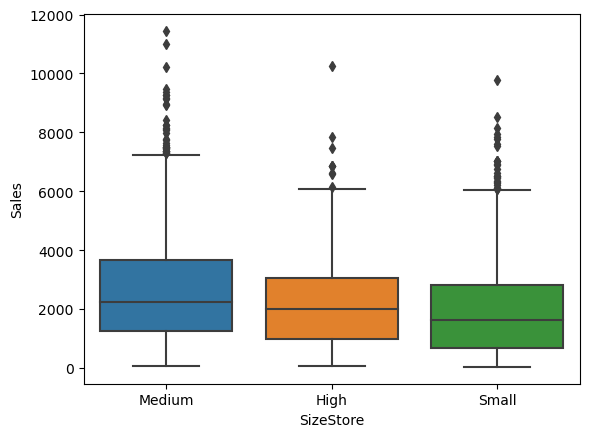

In [26]:
# Studentkode: Bruker the boxplot function
sns.boxplot(x="SizeStore", y="Sales", data=frame)

<Axes: xlabel='StoreType', ylabel='Sales'>

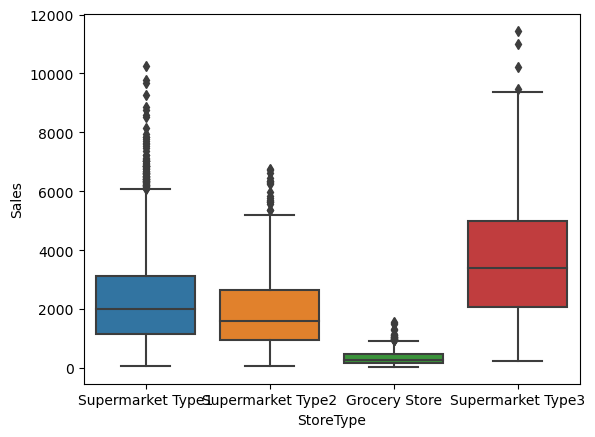

In [27]:
# Studentkode: Bruker the boxplot function
sns.boxplot(x="StoreType", y="Sales", data=frame)

<Axes: xlabel='FatContent', ylabel='Sales'>

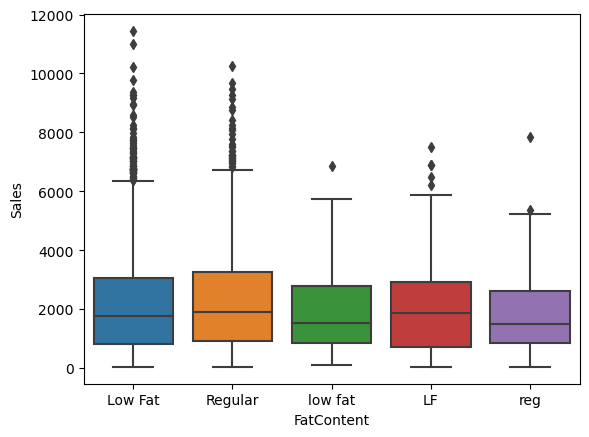

In [28]:
# Studentkode: Bruker the boxplot function
sns.boxplot(x="FatContent", y="Sales", data=frame)

_**Fritekstoppgave**:_

8. _Hvilke variabler tror du kan komme til å påvirke salget basert på den analysen du har gjort? Begrunn svaret ditt._

**Svar**:

Jeg oppdager en middels stor korrelasjon mellom MRP og Salg (r=0,57) som gir en god pekepinn å bruke denne variablen videre. Visibility har derimot bare en r=-0,14 Dvs. en såpass liten correlasjonskoeffisient at den kan droppes siden den gir ikke mye informasjon for gode prediksjoner. Støtter denne vurderingen på pensumlektyre "Scatterplots and Correlation fra Diana Mindrila, Ph.D. og Phoebe Balentyne, M.Ed. Based on Chapter 4 of The Basic Practice of Statistics (6th ed.) hvor tolkning av pearsons correlasjonsverdier er forklart tilsvarende

Videre virker det som om SizeStore variablen har noe å si om Salg. Det er ikke den største variasjonen der, men kan hjelpe med prediksjonene siden det er synlig forskjell mellom de ulike kategriene. Jeg observerer imens at min "Undefined" kategori peker i retning av å være butikker i minste størrelseskategori. Noe jeg hadde allerede mistanker om, så de kunne jeg også droppe eller oversette til small siden de gir ikke mye info.

Jeg kan ikke se noe særlig variasjon i FatContent og Salg og vil si at denne variablen kan droppes. Boksplotten viser at de kommer rimelig likt ut og da får jeg ikke mye ut av det å ta den med videre.

StoreType/Salg boksplotten viser noen tydelige forskjeller mellom de ulike typer ihht salgstall. Dvs jeg vil beholde denne variablen videre.

## Modell

Du skal nå trene en modell som bruker informasjon om et produkt og en butikk til å predikere salget av det produktet i den butikken. Du skal benytte XGBoost og kan starte med å bruke alle de uavhenige variablene (unntatt ProductID, som du allerede har utelukket). Notebook 2 fra modul 2 inneholder både forklaring og eksempel på bruk av XGBoost. Før du trener modellen, må du splitte opp dataene og preprossere dem. Husk at kunden sitter på testdataene, slik at du i dette tilfellet ikke selv trenger å holde av data til testing.

_**Kodeoppgave 4**:_
- _Del inn i trenings- og valideringsdata, og gjør preprosessering av data._

> **Hint**: Tenk på hvilke typer av preprosessering du trenger å gjøre på dataene. Beskrivelse av preprosessering finner du i notebooken til modul 3. I dette tilfellet er det helt greit å gjøre en-hot-koding (one-hot encoding) med den enkle koden vist nedenfor. Det er også greit å gjøre det før du deler opp data, fordi vi antar at alle kategorier vil være representert i både trenings-, validerings- og testdataene.
>```
>frame_processed=pd.get_dummies(frame)
>```

In [29]:
# Studentkode: Starter med One-hor encoding
#frame_processed=pd.get_dummies(frame)

In [30]:
#Studentcode: Gjettet meg fram basert på Modul3 koden hvordan jeg visualiserer resultatet
#frame_processed

,Visibility,MRP,Sales,ProductID_DRA12,ProductID_DRA24,ProductID_DRA59,ProductID_DRB01,ProductID_DRB13,ProductID_DRB24,ProductID_DRB25,...,FatContent_Regular,FatContent_low fat,FatContent_reg,StoreType_Grocery Store,StoreType_Supermarket Type1,StoreType_Supermarket Type2,StoreType_Supermarket Type3,SizeStore_High,SizeStore_Medium,SizeStore_Small
0,0.016047,249.8092,3735.1380,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
1,0.019278,48.2692,443.4228,False,False,False,False,False,False,False,...,True,False,False,False,False,True,False,False,True,False
2,0.016760,141.6180,2097.2700,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
3,-99.000000,182.0950,732.3800,False,False,False,False,False,False,False,...,True,False,False,True,False,False,False,False,False,False
4,-99.000000,53.8614,994.7052,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,0.077476,255.3330,4870.3270,False,False,False,False,False,False,False,...,True,False,False,False,True,False,False,False,False,False
4996,0.027059,153.3682,914.8092,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,True
4997,0.126200,178.4028,1239.7196,False,False,False,False,False,False,False,...,True,False,False,False,False,True,False,False,True,False
4998,0.119462,182.7976,1810.9760,False,False,False,False,False,False,False,...,True,False,False,False,True,False,False,False,False,True


In [34]:
#one hot encoding goes here
frame = cleanframe
frame_processed=pd.get_dummies(frame)
#Spliting the data
X_train, X_eval, y_train, y_eval = train_test_split(
    frame_processed.drop(columns="Sales"), frame["Sales"], test_size=0.20, random_state=1)

#Scaling
scalerX = MinMaxScaler()
scalerX.fit(X_train)
X_train = scalerX.transform(X_train)
X_eval = scalerX.transform(X_eval)
frame_processed

,Visibility,MRP,Sales,FatContent_Low Fat,FatContent_Regular,StoreType_Grocery Store,StoreType_Supermarket Type1,StoreType_Supermarket Type2,StoreType_Supermarket Type3,SizeStore_High,SizeStore_Medium,SizeStore_Small
0,0.016047,249.8092,3735.1380,True,False,False,True,False,False,False,True,False
1,0.019278,48.2692,443.4228,False,True,False,False,True,False,False,True,False
2,0.016760,141.6180,2097.2700,True,False,False,True,False,False,False,True,False
6,0.012741,57.6588,343.5528,False,True,False,True,False,False,True,False,False
7,0.127470,107.7622,4022.7636,True,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
4994,0.010382,207.8954,2292.3494,True,False,False,True,False,False,False,True,False
4996,0.027059,153.3682,914.8092,True,False,False,True,False,False,False,False,True
4997,0.126200,178.4028,1239.7196,False,True,False,False,True,False,False,True,False
4998,0.119462,182.7976,1810.9760,False,True,False,True,False,False,False,False,True


### XGBoost-modell
Når du nå skal lage en XGBoost-modell, kan du starte med å bruke standardverdier for flest mulig av hyperparameterene. Det eneste du skal ta stilling til, er dybden på træerne og evalueringsmetrikken. Her er et kode-eksempel uten hyperparameter-verdier:
```
params = {'max_depth': , 'objective': }
xgb_model = xgb.train(params=params, 
                       dtrain=xgb.DMatrix(X_train, label=y_train))
predicted = xgb_model.predict(xgb.DMatrix(X_eval))
```

_**Kodeoppgave 5**:_
- _Plott prediksjonene og y_eval for å sjekke at modellen predikerer meningsfylt._

> Hint: Du kan f.eks. bruke følgende kode:
> ```
> x = range(len(y_eval))
> plt.scatter(x, y_eval, label='y_eval')
> plt.scatter(x, predicted, label='predicted')
> plt.legend()
> ```

In [39]:
#Studenkode: Gjør et forsøk å splitte data i trainings og valideringsdata. Kode fra modul2 modifisert uten testdata
#train_frac = 1
#val_frac = 0.2                  

In [40]:
#Studenkode: 
#train_split_index = int(train_frac*len(frame))
#val_split_index = int(val_frac*train_split_index) 
#data_train = frame.iloc[:train_split_index]
#data_val = frame.iloc[train_split_index-val_split_index:train_split_index]      

In [41]:
#Studentkode: plot prediksjoner:
#params = {'max_depth': 2, 'objective': "reg:squarederror"}
#xgb_model = xgb.train(params=params, 
#                       dtrain=xgb.DMatrix(data_train, label=y_train))
#predicted = xgb_model.predict(xgb.DMatrix(X_eval))

In [42]:
#Training

params = {'max_depth': 6, 'objective':'reg:squarederror'}
xgb_model = xgb.train(params=params, 
                       dtrain=xgb.DMatrix(X_train, label=y_train))
predicted = xgb_model.predict(xgb.DMatrix(X_eval))

In [ ]:
#Then continue with the scatterplot here


## Modell-evaluering
_**Kodeoppgave 6**:_
- _Evaluer modellen din med RMSE og R2._

> Hint: Du kan benytte funksjonene `mean_squared_error` og `r2_score` fra scikit-learn som vi lastet inn på starten. Se eksempler i modul 3.

In [ ]:
# Studentkode: hentet fra notebook til modul3

print("RMSE validering", np.sqrt(mean_squared_error(y_eval, predicted)))
print("R2 validering", r2_score(y_eval,predicted))

_**Fritekstoppgaver**:_

9. _Beskriv minst én fordel og én ulempe ved XGBoost._
10. _Forklar forskjellen på RMSE og R2._
11. _Fungerte modellen like godt på valideringsdataene som på treningsdataene? Hvis ikke, forklar hvorfor. Kan du bruke dette til å forbedre modellen?_ 

**Svar**:

9.I følge Cheshta Dhingras artikkel "A Visual Guide to Gradient Boosted Trees (XGBoost)" som var del av pensumlektyren har XGBoost mye modelleringskapasitet og jobber raskt selv med komplekse probemstillinger. Ulempen er at det kan ende fort med overtilpasning og det er derfor viktig å gå forsiktig frem 

10. RMSE gir meg informasjon hvor langt jeg er fra den sanne verdien. Den kommer med samme enhet som dataene mine dvs. jeg fikk. jeg ser altså på et tall som oppgir i valuta rupi hvor langt jeg er fra riktig prediksjon. 0 rupi hadde betydd modellen hadde predikert nøyaktig riktig. 

R2 verdien sier meg noe om det hvor godt forklart variasjonen i dataene er forklart. 

11.

### Eksperimenter med å ta vekk variabler
_**Kodeoppgave 7**:_
- _Forsøk å ta vekk variabler du tror ikke er signifikante basert på den utforskende analysen._

> Hint: Du finner eksempler i modul 3.

In [ ]:
# Studentkode

# (Skriv din kode her. Lag gjerne flere kodeceller.)

_**Fritekstoppgaver**:_

12. _Bør du ta vekk variablene som du tenkte ikke var signifikante?_
13. _Hva kan gjøres for å forbedre modellen?_

**Svar**:

(Besvar oppgavene her)